# Laboratorio 9: Visualización estática

## Avance del documento de explicación

**Curso:** CC3084 - Data Science  
**Integrantes:** Milton Polanco y Osman de León  
**Fecha:** 15 de octubre de 2026

Este notebook prepara la evidencia y las decisiones de diseño para una infografía ejecutiva sobre el flujo turístico hacia Guatemala. El avance incluye la validación de cifras, las visualizaciones preliminares y la generación del documento PDF de explicación solicitado.

## 1. Alcance del avance

La pieza final responderá la pregunta: **¿Qué nos enseñan 17 años de datos migratorios sobre el turismo en Guatemala y qué debemos anticipar hacia el futuro?**

Para el avance se desarrollan cuatro tareas:

1. Reproducir el filtro utilizado en el Laboratorio 1: `Turista` y `Excursionista`.
2. Validar los indicadores que sostendrán la narrativa.
3. Probar la selección de gráficos, jerarquía, paleta y anotaciones.
4. Generar el documento de explicación en PDF.

La infografía definitiva en PNG y PDF A3 se completará para la entrega final.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch, Rectangle
import seaborn as sns
from PIL import Image as PILImage

import shutil
import subprocess

warnings.filterwarnings("ignore")

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "Base_Migracion_2009-2026jun.xlsx"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reporte" / "figuras"
REPORT_PATH = PROJECT_ROOT / "reporte" / "avance_lab9.pdf"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    "navy": "#17324D",
    "teal": "#2A7F8E",
    "amber": "#F2A900",
    "ink": "#263238",
    "gray": "#6B7280",
    "light": "#EEF3F5",
    "white": "#FFFFFF",
}

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Base disponible: {RAW_PATH.exists()}")

Raíz del proyecto: C:\Users\mdax8\Desktop\UVG\8 Semestre\Data Science\Lab 9
Base disponible: True


## 2. Fuente, filtro y controles de calidad

La fuente es la **Base de Migración 2009-2026 de INGUAT/IGM** utilizada en el Laboratorio 1. El análisis conserva únicamente las categorías `Turista` y `Excursionista` y agrega la variable `Viajero` por mes.

El corte de junio de 2026 no se compara contra años completos. Además, los cambios de registro indicados en las notas de la base para 2022 y 2023 deben mantenerse visibles en la ficha técnica de la infografía.

In [2]:
df = pd.read_excel(RAW_PATH, sheet_name="Datos")
df["Fecha"] = pd.to_datetime(
    {"year": df["Año"], "month": df["Mes cod"], "day": 1}
)

df_turismo = df[df["Tipo de Viajero"].isin(["Turista", "Excursionista"])].copy()
quality_columns = ["Fecha", "País", "Región dos", "Vía", "Frontera", "Viajero"]

print(f"Registros originales: {len(df):,}")
print(f"Registros del filtro turístico: {len(df_turismo):,}")
print(
    "Cobertura:",
    df_turismo["Fecha"].min().strftime("%Y-%m"),
    "a",
    df_turismo["Fecha"].max().strftime("%Y-%m"),
)
print(f"Filas duplicadas: {df_turismo.duplicated().sum():,}")
print("Valores faltantes en campos analíticos:")
display(df_turismo[quality_columns].isna().sum().to_frame("faltantes"))

Registros originales: 161,036
Registros del filtro turístico: 137,642
Cobertura: 2009-01 a 2026-06
Filas duplicadas: 0
Valores faltantes en campos analíticos:


,faltantes
Fecha,0
País,0
Región dos,0
Vía,0
Frontera,0
Viajero,0


## 3. Preparación de series y tablas procesadas

Las tablas agregadas permiten reconstruir los gráficos sin volver a procesar todo el archivo de Excel. Los años 2009-2019 forman la ventana común para calcular crecimiento, estacionalidad y volatilidad sin mezclar el choque de la pandemia con el comportamiento estructural previo.

In [3]:
monthly_total = (
    df_turismo.groupby("Fecha")["Viajero"]
    .sum()
    .asfreq("MS", fill_value=0)
    .rename("viajeros")
)

monthly_route = (
    df_turismo.pivot_table(
        index="Fecha", columns="Vía", values="Viajero", aggfunc="sum", fill_value=0
    )
    .asfreq("MS", fill_value=0)
)

series = {
    "Total": monthly_total,
    "Centroamérica": df_turismo[df_turismo["Región dos"] == "América Del Centro"]
        .groupby("Fecha")["Viajero"].sum().asfreq("MS", fill_value=0),
    "Norteamérica": df_turismo[df_turismo["Región dos"] == "América Del Norte"]
        .groupby("Fecha")["Viajero"].sum().asfreq("MS", fill_value=0),
    "Europa": df_turismo[df_turismo["Región dos"] == "Europa"]
        .groupby("Fecha")["Viajero"].sum().asfreq("MS", fill_value=0),
    "El Salvador": df_turismo[df_turismo["País"] == "El Salvador"]
        .groupby("Fecha")["Viajero"].sum().asfreq("MS", fill_value=0),
    "Guatemala": df_turismo[df_turismo["País"] == "Guatemala"]
        .groupby("Fecha")["Viajero"].sum().asfreq("MS", fill_value=0),
    "EE. UU.": df_turismo[df_turismo["País"] == "Estados Unidos de América"]
        .groupby("Fecha")["Viajero"].sum().asfreq("MS", fill_value=0),
}

prepandemic = monthly_total.loc["2009":"2019"]
seasonal_index = (
    prepandemic.groupby(prepandemic.index.month).mean() / prepandemic.mean() * 100
)
seasonal_index.index = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic",
]
seasonal_index = seasonal_index.rename("indice_estacional")

def comparison_metrics(name, values):
    values = values.asfreq("MS", fill_value=0)
    base = values.loc["2009":"2019"]
    profile = base.groupby(base.index.month).mean() / base.mean()
    annual = base.groupby(base.index.year).sum()
    centered = base.rolling(12, center=True, min_periods=12).mean()
    residual = (base - centered).dropna()
    all_annual = values.groupby(values.index.year).sum()
    return {
        "serie": name,
        "amplitud_estacional_pp": (profile.max() - profile.min()) * 100,
        "cagr_2009_2019_pct": ((annual.loc[2019] / annual.loc[2009]) ** (1 / 10) - 1) * 100,
        "volatilidad_residual_pct": residual.std() / base.mean() * 100,
        "caida_2020_pct": (all_annual.loc[2020] / all_annual.loc[2019] - 1) * 100,
    }

comparison = pd.DataFrame(
    [comparison_metrics(name, values) for name, values in series.items()]
).set_index("serie")

monthly_total.to_frame().to_csv(PROCESSED_DIR / "serie_mensual_total.csv", index_label="fecha")
monthly_route.to_csv(PROCESSED_DIR / "serie_mensual_por_via.csv", index_label="fecha")
seasonal_index.to_frame().to_csv(PROCESSED_DIR / "indice_estacional.csv", index_label="mes")
comparison.to_csv(PROCESSED_DIR / "comparacion_series.csv")

display(comparison.round(2))

,amplitud_estacional_pp,cagr_2009_2019_pct,volatilidad_residual_pct,caida_2020_pct
serie,,,,
Total,52.57,8.19,14.71,-74.35
Centroamérica,64.23,9.83,16.56,-74.43
Norteamérica,68.65,3.81,21.22,-74.14
Europa,58.39,2.33,22.00,-71.83
El Salvador,64.00,11.07,22.42,-79.78
Guatemala,71.01,10.10,17.05,-70.19
EE. UU.,83.59,4.58,26.00,-73.99


## 4. Indicadores para el titular y las tarjetas

El titular propuesto es: **Guatemala recupera el turismo, pero 2025 aún quedó 19% bajo el pico de 2019**.

El mensaje combina una lectura de recuperación con una advertencia verificable. Las tarjetas se limitan a cuatro datos para evitar saturar la parte superior de la infografía.

In [4]:
annual_total = monthly_total.groupby(monthly_total.index.year).sum()
total_period = monthly_total.sum()
land_share = (
    df_turismo.groupby("Vía")["Viajero"].sum().loc["Terrestre"]
    / df_turismo["Viajero"].sum()
)
pandemic_drop = annual_total.loc[2020] / annual_total.loc[2019] - 1
recovery_2025 = annual_total.loc[2025] / annual_total.loc[2019]
december_index = seasonal_index.loc["Dic"]

kpis = pd.DataFrame([
    {"indicador": "Viajeros acumulados", "valor": total_period, "unidad": "personas", "texto": f"{total_period / 1e6:.1f} millones"},
    {"indicador": "Participación terrestre", "valor": land_share, "unidad": "proporción", "texto": f"{land_share:.1%}"},
    {"indicador": "Nivel 2025 frente a 2019", "valor": recovery_2025, "unidad": "proporción", "texto": f"{recovery_2025:.1%}"},
    {"indicador": "Índice estacional de diciembre", "valor": december_index, "unidad": "base 100", "texto": f"{december_index:.1f}"},
])
kpis.to_csv(PROCESSED_DIR / "kpis_avance.csv", index=False)

print(f"Total 2009-junio 2026: {total_period:,.0f}")
print(f"Participación de la vía terrestre: {land_share:.1%}")
print(f"Caída de 2020 frente a 2019: {pandemic_drop:.1%}")
print(f"Nivel de 2025 frente a 2019: {recovery_2025:.1%}")
print(f"Diciembre frente a un mes promedio prepandemia: {december_index - 100:+.1f}%")
display(kpis[["indicador", "texto"]])

Total 2009-junio 2026: 46,711,913
Participación de la vía terrestre: 59.1%
Caída de 2020 frente a 2019: -74.4%
Nivel de 2025 frente a 2019: 81.1%
Diciembre frente a un mes promedio prepandemia: +33.8%


,indicador,texto
0,Viajeros acumulados,46.7 millones
1,Participación terrestre,59.1%
2,Nivel 2025 frente a 2019,81.1%
3,Índice estacional de diciembre,133.8


## 5. Prototipos de las visualizaciones

Los prototipos usan etiquetas directas, una sola escala por gráfico y la misma paleta. El color ámbar se reserva para el dato que requiere atención; el azul petróleo y el turquesa sostienen la lectura principal.

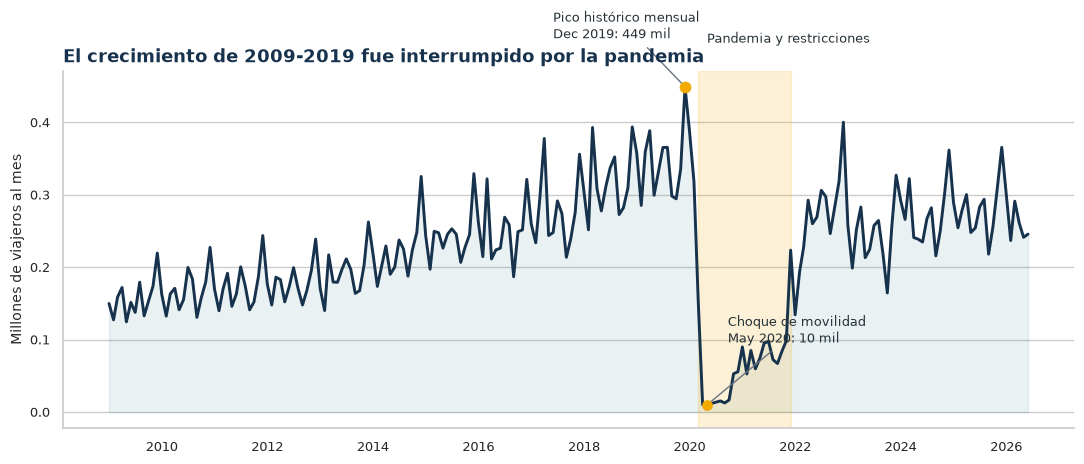

In [5]:
# Panorama histórico mensual
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(monthly_total.index, monthly_total.values / 1e6, color=PALETTE["navy"], lw=2.1)
ax.fill_between(monthly_total.index, monthly_total.values / 1e6, color=PALETTE["teal"], alpha=0.10)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=PALETTE["amber"], alpha=0.16)

peak_date = monthly_total.idxmax()
low_date = monthly_total.loc["2020"].idxmin()
ax.scatter([peak_date], [monthly_total.loc[peak_date] / 1e6], s=55, color=PALETTE["amber"], zorder=5)
ax.scatter([low_date], [monthly_total.loc[low_date] / 1e6], s=45, color=PALETTE["amber"], zorder=5)
ax.annotate(
    f"Pico histórico mensual\n{peak_date:%b %Y}: {monthly_total.loc[peak_date] / 1e3:,.0f} mil",
    xy=(peak_date, monthly_total.loc[peak_date] / 1e6), xytext=(-95, 35),
    textcoords="offset points", fontsize=9, color=PALETTE["ink"],
    arrowprops=dict(arrowstyle="-", color=PALETTE["gray"]),
)
ax.annotate(
    f"Choque de movilidad\n{low_date:%b %Y}: {monthly_total.loc[low_date] / 1e3:,.0f} mil",
    xy=(low_date, monthly_total.loc[low_date] / 1e6), xytext=(15, 45),
    textcoords="offset points", fontsize=9, color=PALETTE["ink"],
    arrowprops=dict(arrowstyle="-", color=PALETTE["gray"]),
)
ax.text(pd.Timestamp("2020-05-01"), 0.51, "Pandemia y restricciones", color=PALETTE["ink"], fontsize=9)
ax.set_title("El crecimiento de 2009-2019 fue interrumpido por la pandemia", loc="left", color=PALETTE["navy"])
ax.set_ylabel("Millones de viajeros al mes")
ax.set_xlabel("")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
timeline_path = FIGURES_DIR / "01_panorama_historico.png"
fig.savefig(timeline_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

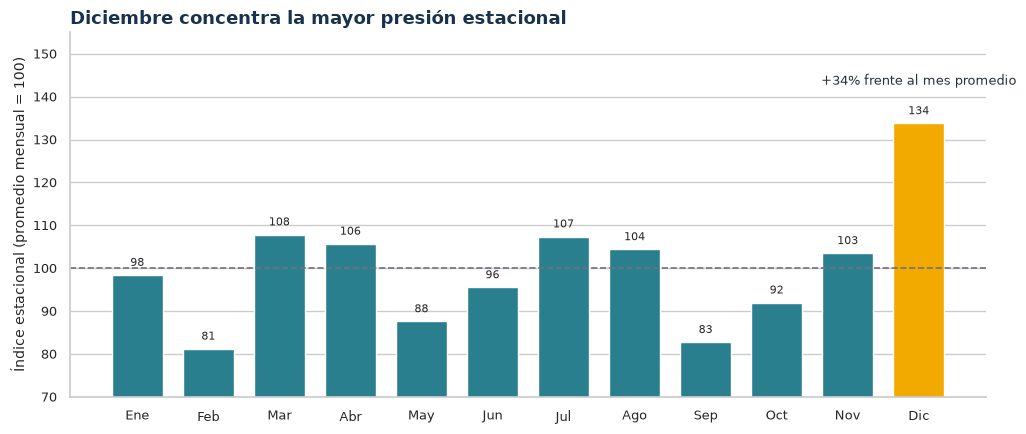

In [6]:
# Perfil estacional prepandemia
fig, ax = plt.subplots(figsize=(10.5, 4.5))
bar_colors = [PALETTE["teal"]] * 11 + [PALETTE["amber"]]
bars = ax.bar(seasonal_index.index, seasonal_index.values, color=bar_colors, width=0.72)
ax.axhline(100, color=PALETTE["gray"], lw=1.2, linestyle="--")
for bar, value in zip(bars, seasonal_index.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.0f}", ha="center", va="bottom", fontsize=8)
ax.text(11, seasonal_index.loc["Dic"] + 9, "+34% frente al mes promedio", ha="center", fontsize=9, color=PALETTE["ink"])
ax.set_ylim(70, 155)
ax.set_title("Diciembre concentra la mayor presión estacional", loc="left", color=PALETTE["navy"])
ax.set_ylabel("Índice estacional (promedio mensual = 100)")
ax.set_xlabel("")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
seasonality_path = FIGURES_DIR / "02_estacionalidad_mensual.png"
fig.savefig(seasonality_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

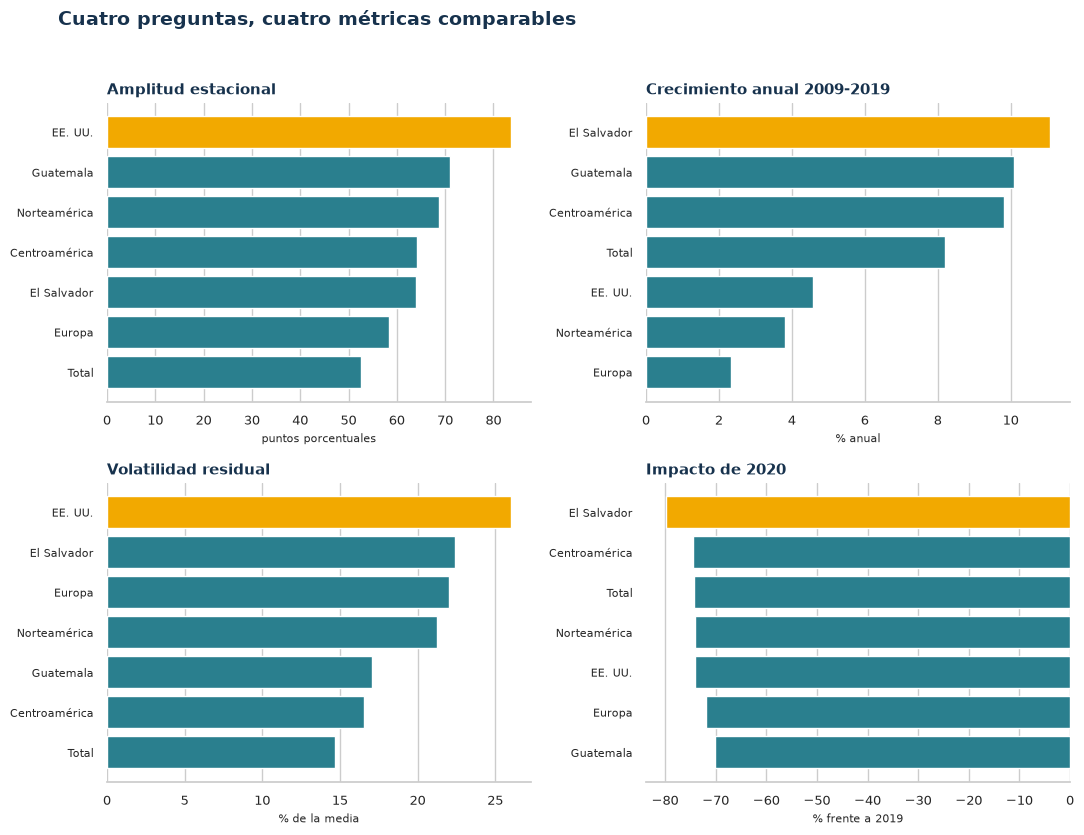

In [7]:
# Comparación de las series con definiciones homogéneas
metrics_to_plot = [
    ("amplitud_estacional_pp", "Amplitud estacional", "puntos porcentuales"),
    ("cagr_2009_2019_pct", "Crecimiento anual 2009-2019", "% anual"),
    ("volatilidad_residual_pct", "Volatilidad residual", "% de la media"),
    ("caida_2020_pct", "Impacto de 2020", "% frente a 2019"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for ax, (column, title, unit) in zip(axes.flat, metrics_to_plot):
    values = comparison[column].copy()
    ranking = values.abs().sort_values(ascending=True)
    colors_plot = [PALETTE["teal"]] * len(ranking)
    colors_plot[-1] = PALETTE["amber"]
    ax.barh(ranking.index, values.loc[ranking.index], color=colors_plot)
    ax.set_title(title, loc="left", color=PALETTE["navy"], fontsize=11)
    ax.set_xlabel(unit, fontsize=8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Cuatro preguntas, cuatro métricas comparables", x=0.06, ha="left", fontsize=14, fontweight="bold", color=PALETTE["navy"])
fig.tight_layout(rect=[0, 0, 1, 0.96])
comparison_path = FIGURES_DIR / "03_comparacion_series.png"
fig.savefig(comparison_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

### Comparación de modelos del Laboratorio 1

Para conservar la trazabilidad con el laboratorio anterior, la comparación utiliza las métricas reportadas para la serie total en el conjunto de prueba. El RMSE se elige como indicador principal porque penaliza con mayor fuerza los errores grandes, relevantes para planificación de capacidad.

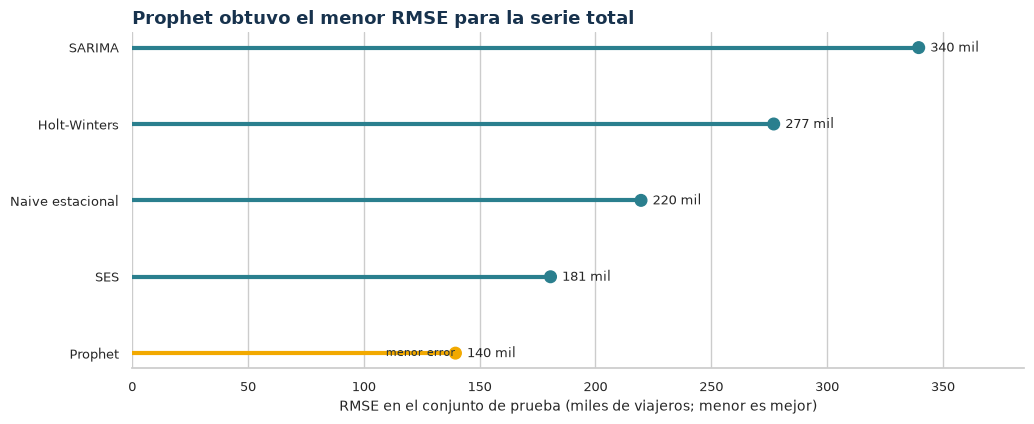

,modelo,mae,rmse
0,Prophet,132304.57,139548.88
1,SES,165370.15,180595.74
2,Naive estacional,207321.64,219663.87
3,Holt-Winters,255821.04,276949.07
4,SARIMA,310713.29,339542.89


In [8]:
model_metrics = pd.DataFrame([
    {"modelo": "Prophet", "mae": 132304.57, "rmse": 139548.88},
    {"modelo": "SES", "mae": 165370.15, "rmse": 180595.74},
    {"modelo": "Naive estacional", "mae": 207321.64, "rmse": 219663.87},
    {"modelo": "Holt-Winters", "mae": 255821.04, "rmse": 276949.07},
    {"modelo": "SARIMA", "mae": 310713.29, "rmse": 339542.89},
]).sort_values("rmse")
model_metrics.to_csv(PROCESSED_DIR / "metricas_modelos_serie_total.csv", index=False)

fig, ax = plt.subplots(figsize=(10.5, 4.4))
colors_models = [PALETTE["amber"]] + [PALETTE["teal"]] * (len(model_metrics) - 1)
ax.hlines(model_metrics["modelo"], 0, model_metrics["rmse"] / 1e3, color=colors_models, lw=3)
ax.scatter(model_metrics["rmse"] / 1e3, model_metrics["modelo"], color=colors_models, s=70, zorder=3)
for _, row in model_metrics.iterrows():
    ax.text(row["rmse"] / 1e3 + 5, row["modelo"], f'{row["rmse"] / 1e3:,.0f} mil', va="center", fontsize=9)
ax.text(model_metrics.iloc[0]["rmse"] / 1e3, model_metrics.iloc[0]["modelo"], "   menor error", va="center", ha="right", fontsize=8, color=PALETTE["ink"])
ax.set_xlim(0, 385)
ax.set_title("Prophet obtuvo el menor RMSE para la serie total", loc="left", color=PALETTE["navy"])
ax.set_xlabel("RMSE en el conjunto de prueba (miles de viajeros; menor es mejor)")
ax.set_ylabel("")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
models_path = FIGURES_DIR / "04_comparacion_modelos.png"
fig.savefig(models_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

display(model_metrics.reset_index(drop=True))

## 6. Arquitectura visual propuesta

La composición seguirá una lectura vertical. El titular y los indicadores entregan la conclusión primero; luego la línea histórica explica el contexto; la estacionalidad y la comparación de mercados profundizan el diagnóstico; los modelos abren la mirada al futuro; y las recomendaciones cierran con acciones para INGUAT.

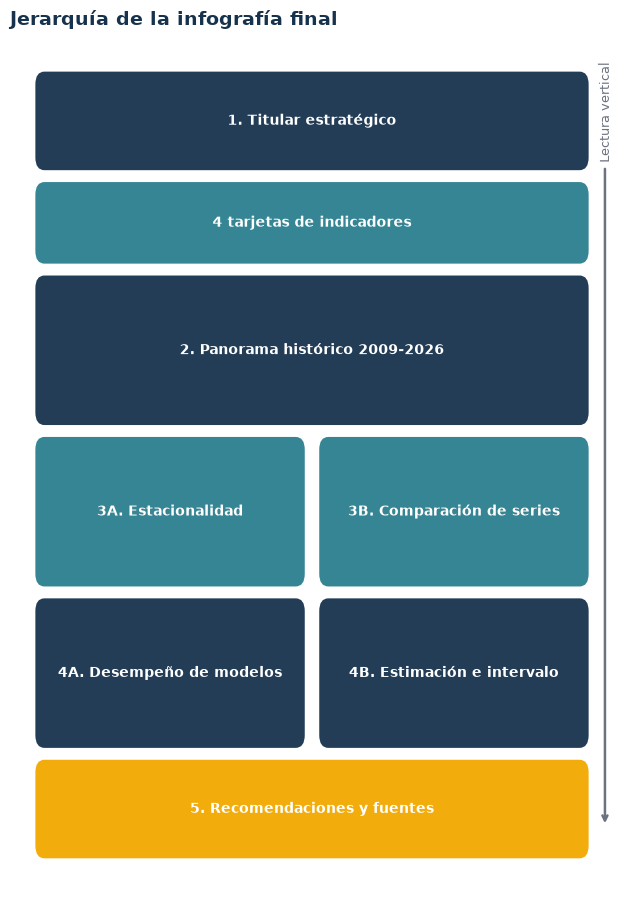

In [9]:
# Esquema de lectura de la infografía final
fig, ax = plt.subplots(figsize=(6.4, 9.2))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

blocks = [
    (0.05, 0.86, 0.90, 0.10, "1. Titular estratégico", PALETTE["navy"]),
    (0.05, 0.75, 0.90, 0.08, "4 tarjetas de indicadores", PALETTE["teal"]),
    (0.05, 0.56, 0.90, 0.16, "2. Panorama histórico 2009-2026", PALETTE["navy"]),
    (0.05, 0.37, 0.43, 0.16, "3A. Estacionalidad", PALETTE["teal"]),
    (0.52, 0.37, 0.43, 0.16, "3B. Comparación de series", PALETTE["teal"]),
    (0.05, 0.18, 0.43, 0.16, "4A. Desempeño de modelos", PALETTE["navy"]),
    (0.52, 0.18, 0.43, 0.16, "4B. Estimación e intervalo", PALETTE["navy"]),
    (0.05, 0.05, 0.90, 0.10, "5. Recomendaciones y fuentes", PALETTE["amber"]),
]

for x, y, w, h, label, color in blocks:
    patch = FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.008,rounding_size=0.015",
        linewidth=0, facecolor=color, alpha=0.95
    )
    ax.add_patch(patch)
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", color="white", fontsize=10, fontweight="bold")

ax.annotate("Lectura vertical", xy=(0.985, 0.08), xytext=(0.985, 0.92),
            arrowprops=dict(arrowstyle="->", lw=1.8, color=PALETTE["gray"]),
            rotation=90, ha="center", va="center", color=PALETTE["gray"], fontsize=9)
ax.set_title("Jerarquía de la infografía final", loc="left", color=PALETTE["navy"], fontsize=14, pad=14)
fig.tight_layout()
wireframe_path = FIGURES_DIR / "05_esquema_infografia.png"
fig.savefig(wireframe_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 8. Archivos producidos

- `reporte/avance_lab9.pdf`: documento de explicación compilado.
- `reporte/figuras/`: prototipos visuales incluidos en el documento.
- `data/processed/`: tablas agregadas y métricas utilizadas.

La infografía final de una página no forma parte de este avance y queda pendiente para la fecha de entrega indicada en el enunciado.